In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression 
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
import numpy as np

In [51]:
# DATASET
# https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv
warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv('insurance.csv')

In [6]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
df.shape

(1338, 7)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
df.duplicated().sum()

1

In [14]:
df = df.drop_duplicates().reset_index(drop=True)

In [15]:
df.duplicated().sum()

0

In [16]:
# Explore data and correlations

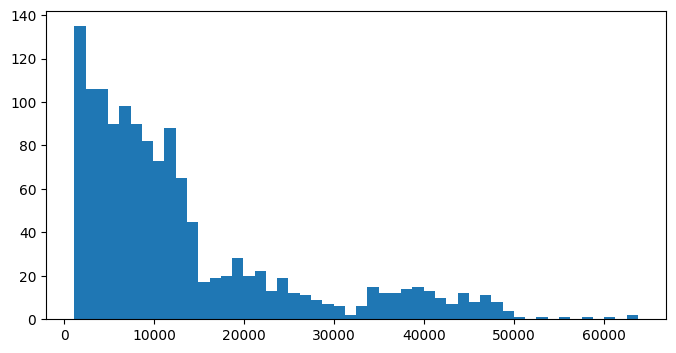

In [20]:
# Target distribution
plt.figure(figsize=(8, 4))
plt.hist(df['charges'], bins=50)
plt.show()

Text(0.5, 1.0, 'Region')

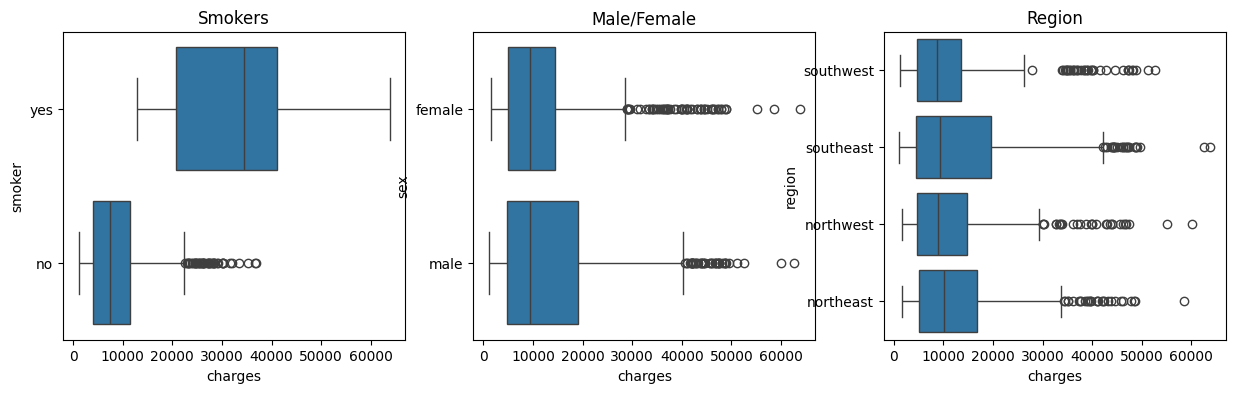

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x="charges", y="smoker", data=df, ax=axes[0])
axes[0].set_title("Smokers")
sns.boxplot(x="charges", y="sex", data=df, ax=axes[1])
axes[1].set_title("Male/Female")
sns.boxplot(x="charges", y="region", data=df, ax=axes[2])
axes[2].set_title("Region")

<Axes: xlabel='bmi', ylabel='charges'>

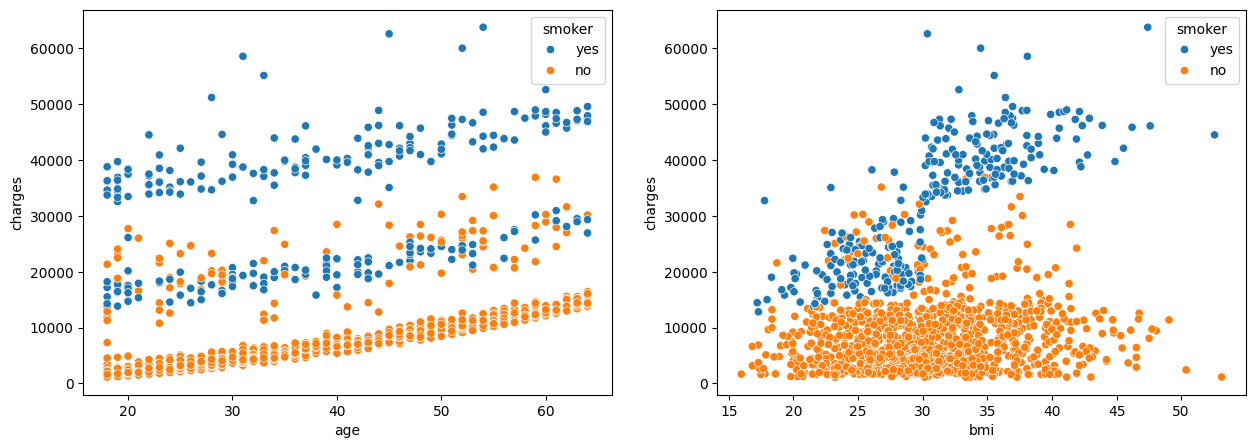

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", ax=axes[0])
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", ax=axes[1])

In [42]:
# ML - Create Model and Predict

In [43]:
df['sex'].unique()

array(['female', 'male'], dtype=object)

In [44]:
df['smoker'].unique()

array(['yes', 'no'], dtype=object)

In [45]:
df['region'].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

In [46]:
# df['sex'] = df['sex'].map({'female': 1, 'male': 0})

In [54]:
features = ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
target = 'charges'

In [55]:
X = df[features]
y = df[target]

In [56]:
X['sex'] = X['sex'].map({'female': 1, 'male': 0})

In [58]:
X['smoker'] = X['smoker'].map({'yes': 1, 'no': 0})

In [60]:
X = pd.get_dummies(X, columns=['region'], dtype=int)

In [61]:
X.head()

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,0,0,0,1
1,18,0,33.770,1,0,0,0,1,0
2,28,0,33.000,3,0,0,0,1,0
3,33,0,22.705,0,0,0,1,0,0
4,32,0,28.880,0,0,0,1,0,0


In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [63]:
linear_model = LinearRegression()

In [64]:
linear_model.fit(X_train, y_train)

LinearRegression()

In [65]:
prediction = linear_model.predict(X_test)

In [66]:
mean_absolute_error(y_test, prediction)

4177.045561036318

In [69]:
np.sqrt(mean_squared_error(y_test, prediction))

5956.342894363587

In [70]:
r2_score(y_test, prediction)

0.8069287081198012

In [71]:
forest_model = RandomForestRegressor()

In [72]:
forest_model.fit(X_train, y_train)

RandomForestRegressor()

In [73]:
prediction = forest_model.predict(X_test)

In [74]:
mean_absolute_error(y_test, prediction)

2560.7287816425373

In [75]:
np.sqrt(mean_squared_error(y_test, prediction))

4612.919593986821

In [76]:
r2_score(y_test, prediction)

0.8841995920426974